# PER3 genotype and clock-gene timing: live demo

A short, interactive version of our analysis for the presentation. The full analysis (8 stages,
~9 min to run) is in [`PER3_clock_timing.ipynb`](PER3_clock_timing.ipynb).

**Before the talk (warm-up, ~2 min):** *Runtime → Run all*. This installs the package, downloads the
data (~100 MB from GEO) and runs every demo cell once, so nothing slow happens on stage.

**During the talk:** change a dropdown on the right of a demo cell, then run that cell
(**Shift + Enter**). Each demo cell takes a few seconds.

| Demo | Shows | Uses |
|---|---|---|
| 1 | One person's clock gene rising and falling, and its peak time | cosinor fit |
| 2 | Early birds (5/5) vs night owls (4/4): peak times, shift and 95 % CI, on clock time vs melatonin time | circular statistics |
| 3 | Predicting a new person's internal clock time from their blood | leave-one-person-out ridge model |
| 4 | Our saved full results (fallback if anything breaks) | saved tables and figures |

In [1]:
# @title Setup: install the package (Colab)
# --- Colab bootstrap: in Colab, clone + install the repo; locally, do nothing ---
import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/CKmellow/per3-genotype-clock-gene-timing.git"
BRANCH = "feat/live-demo"  # @param ["feat/live-demo", "main"]
# use "main" once the live-demo PR is merged
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    repo = Path("/content/per3-genotype-clock-gene-timing")
    if not repo.exists():
        subprocess.run(["git", "clone", "--depth", "1", "-b", BRANCH, REPO_URL, str(repo)], check=True)
    os.chdir(repo)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", "."], check=True)
    src = str(repo / "src")
else:  # local: find the repo root (works from notebooks/ or notebooks/stages/)
    here = Path.cwd().resolve()
    root = next((p for p in [here, *here.parents] if (p / "pyproject.toml").exists()), here)
    src = str(root / "src")
if src not in sys.path:
    sys.path.insert(0, src)  # makes `import per3clock` work without a kernel restart

from per3clock import config  # noqa: E402

config.set_seeds()
config.ensure_dirs()
print("per3clock root:", config.ROOT, "| Colab:", IN_COLAB)

per3clock root: /home/cyprian/name/str/4.2/bioinformatics/per3-genotype-clock-gene-timing | Colab: False


## Warm-up: load the data
Run before the talk. Loads clock genes (small file in the repo) and the genome-wide matrix (downloaded once from GEO).

In [2]:
# @title Warm-up: load the data
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

from per3clock import circstats, data, ml, plotting, rhythm

warnings.filterwarnings("ignore")
plotting.set_style()
pd.set_option("display.width", 160)
COL = plotting.GENOTYPE_COLORS
t0 = time.time()

meta = data.load_metadata()
main = data.analysis_samples(metadata=meta)                                 # 24 people, 221 samples
phase_set = data.analysis_samples(metadata=meta, for_phase_analysis=True)  # 23 people, 214 samples
clock = data.load_clock_genes()
clock_main = clock[clock.sample_id.isin(main.sample_id)]
clock_phase = clock[clock.sample_id.isin(phase_set.sample_id)]

# Genome-wide matrix for demo 3 (the slow part: ~100 MB download, done once)
ml_meta = phase_set.reset_index(drop=True)
groups = ml_meta["subject"].to_numpy()
true_phase = np.mod(ml_meta["circadian_phase_h"].to_numpy(), 24)
expressed = pd.read_csv(config.PROCESSED_DIR / "expressed_genes_SE.csv")["gene"].tolist()
genome = data.collapse_probes_to_genes(data.load_expression_matrix(dtype="float32"))
X_centred = ml.within_subject_centre(genome.loc[expressed, ml_meta["sample_id"]].T
                                     .reset_index(drop=True), groups)
X_clock_time = ml.clock_features(ml_meta)

people = main.drop_duplicates("subject").per3_genotype.value_counts()
print(f"{main.subject.nunique()} people ({people['4/4']} x 4/4 night owls, {people['5/5']} x 5/5 early birds), "
      f"{len(main)} blood samples, {X_centred.shape[1]:,} expressed genes")
print(f"ready in {time.time() - t0:.0f} s")

24 people (11 x 4/4 night owls, 13 x 5/5 early birds), 221 blood samples, 17,528 expressed genes
ready in 5 s


## Demo 1: one person's body clock
Each dot is one blood sample, taken every 3 hours while the person stayed awake for ~40 hours.
The line is the fitted 24-hour cosine wave (cosinor). Its top is the **peak time** (acrophase)
that we compare between genotypes.

*Try:* NR1D1 for AF0295 (a very clear rhythm); AF0286 (a 4/4 night owl); then AF0101, whose PER3
barely has a rhythm (p ≈ 0.9). Single peak times are noisy, which is why we compare groups with
confidence intervals.

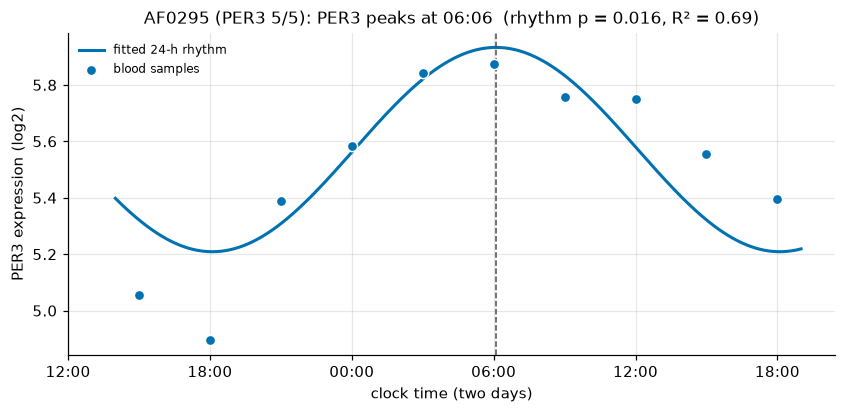

In [3]:
# @title Demo 1: one person's body clock
GENE = "PER3"  # @param ["PER3", "PER2", "NR1D1", "PER1", "CRY1", "NR1D2", "ARNTL", "CLOCK"]
PERSON = "AF0295"  # @param ["AF0004", "AF0010", "AF0033", "AF0069", "AF0089", "AF0094", "AF0101", "AF0112", "AF0114", "AF0122", "AF0139", "AF0145", "AF0164", "AF0186", "AF0191", "AF0205", "AF0212", "AF0214", "AF0267", "AF0286", "AF0295", "AF0318", "AF0335"]

d = clock_main[(clock_main.gene == GENE) & (clock_main.subject == PERSON)].sort_values("timepoint_n")
t = d["clock_time_h"].to_numpy().copy()
t[1:] += 24 * np.cumsum(np.diff(t) < 0)          # unwrap past midnight: 18:00, 21:00, 24:00, 27:00, ...
fit = rhythm.cosinor_fit(t, d["expression"])
gt = d["per3_genotype"].iloc[0]

tt = np.linspace(t.min() - 1, t.max() + 1, 300)
wave = fit["mesor"] + fit["amplitude"] * np.cos(2 * np.pi * (tt - fit["acrophase_h"]) / 24)
peaks = fit["acrophase_h"] + 24 * np.arange(0, 3)
peaks = peaks[(peaks >= tt.min()) & (peaks <= tt.max())]

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(tt, wave, color=COL[gt], lw=2, label="fitted 24-h rhythm")
ax.scatter(t, d["expression"], color=COL[gt], s=45, zorder=3, edgecolor="white", label="blood samples")
for p in peaks:
    ax.axvline(p, color="0.3", ls="--", lw=1)
ax.set_xticks(np.arange(np.floor(tt.min() / 6) * 6, tt.max() + 1, 6))
ax.set_xticklabels([f"{int(h % 24):02d}:00" for h in ax.get_xticks()])
ax.set_xlabel("clock time (two days)")
ax.set_ylabel(f"{GENE} expression (log2)")
ax.set_title(f"{PERSON} (PER3 {gt}): {GENE} peaks at {int(fit['acrophase_h']):02d}:"
             f"{int(round(fit['acrophase_h'] % 1 * 60)) % 60:02d}  (rhythm p = {fit['p']:.2g}, R² = {fit['r2']:.2f})")
ax.legend(loc="upper left", fontsize=8)
plt.show()

## Demo 2: early birds vs night owls
The same fit for **every** person. Each dot on the dial is one person's peak time (orange = 4/4
night owls, blue = 5/5 early birds); arrows are the group averages. Left: clock time. Right:
time measured from each person's own melatonin rhythm (internal clock).

The table gives the shift (5/5 − 4/4; negative = early birds peak earlier) with a bootstrap 95 % CI
and a permutation p-value (2,000 resamples here for speed; the full analysis uses 10,000).

*Try:* NR1D1: 5/5 peaks ~1.2 h earlier on clock time but ~0 h on melatonin time. For every gene
and both time axes the 95 % CI crosses zero: no detectable shift with 11 vs 13 people.

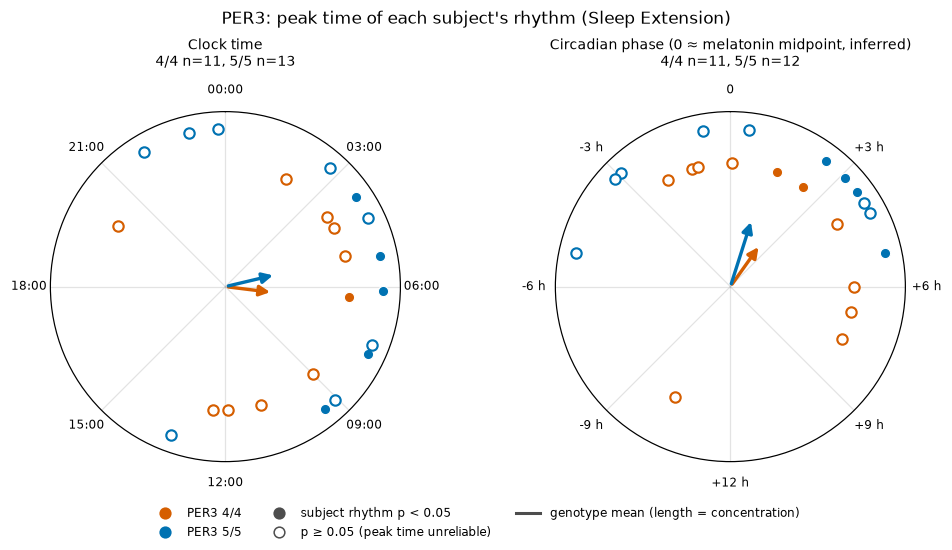

PER3 on clock time      shift -1.36 h  [95% CI -6.38, +3.13]  p = 0.57  (n = 11 vs 13)  -> CI crosses 0: no clear shift
PER3 on melatonin time  shift -1.18 h  [95% CI -5.53, +2.22]  p = 0.51  (n = 11 vs 12)  -> CI crosses 0: no clear shift


In [4]:
# @title Demo 2: early birds vs night owls
GENE = "PER3"  # @param ["PER3", "PER2", "NR1D1", "PER1", "CRY1", "NR1D2", "ARNTL", "CLOCK"]

fits = pd.concat([
    rhythm.fit_subject_cosinors(clock_main, time_col="clock_time_h", genes=(GENE,)).assign(time_base="clock_time"),
    rhythm.fit_subject_cosinors(clock_phase, time_col="circadian_phase_h", genes=(GENE,)).assign(time_base="circadian_phase"),
])
plotting.plot_acrophase_rose(fits, GENE)
plt.show()

tests = circstats.genotype_shift_table(fits, by=("gene", "time_base"), n_perm=2000, n_boot=2000)
axis_name = {"clock_time": "clock time", "circadian_phase": "melatonin time"}
for _, r in tests.iterrows():
    verdict = "CI crosses 0: no clear shift" if r.ci_lower_h < 0 < r.ci_upper_h else "CI excludes 0"
    print(f"{GENE} on {axis_name[r.time_base]:<15} shift {r.shift_h:+.2f} h  "
          f"[95% CI {r.ci_lower_h:+.2f}, {r.ci_upper_h:+.2f}]  p = {r.permutation_p:.2f}  "
          f"(n = {r.n_44} vs {r.n_55})  -> {verdict}")

## Demo 3: can blood tell a new person's internal clock time?
We hide one person completely, train on the other 22, then predict the hidden person's melatonin
phase for each of their blood samples. Two predictors:

* **Clock time only** (baseline): the wall clock plus the average clock-to-melatonin offset.
* **Clock time + 50 genes**: a ridge model that also uses the 50 most rhythmic genes, picked
  from the 22 training people only (each person's own average expression removed first).

*Try:* another person. Across all 23 people the gene model is better for 18
(0.77 h vs 1.08 h median error).

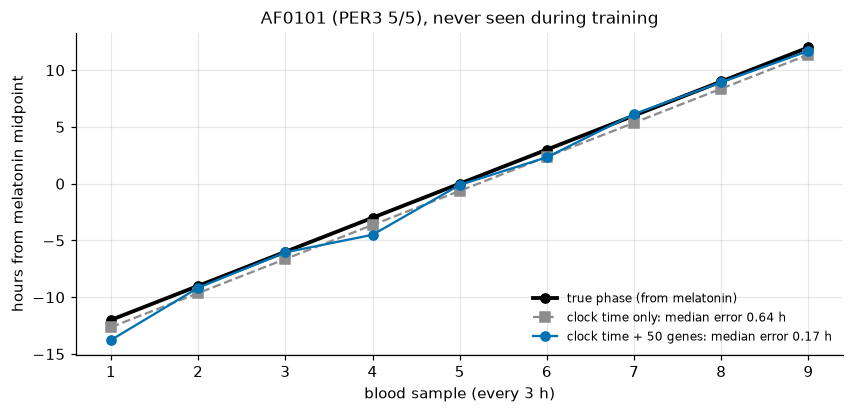

a few of the 50 genes the model picked: ABHD5, ABTB1, AK5, ALOX5AP, AVIL, B4GALT5, BCL11B, C2orf89, CEP68, CLEC4E


In [5]:
# @title Demo 3: predict a new person's internal clock
PERSON = "AF0101"  # @param ["AF0004", "AF0010", "AF0033", "AF0069", "AF0089", "AF0094", "AF0101", "AF0112", "AF0114", "AF0122", "AF0139", "AF0145", "AF0164", "AF0186", "AF0191", "AF0205", "AF0212", "AF0214", "AF0267", "AF0286", "AF0295", "AF0318", "AF0335"]

test = groups == PERSON
train = ~test
Y = ml.encode_phase(true_phase)
X_full = pd.concat([X_clock_time, X_centred], axis=1)

baseline = ml.ClockOffsetBaseline().fit(X_clock_time[train], Y[train])
model = ml.ridge_pipeline(k=50, keep_first=2).fit(X_full[train], Y[train])
pred_base = ml.decode_phase(baseline.predict(X_clock_time[test]))
pred_model = ml.decode_phase(model.predict(X_full[test]))
truth = true_phase[test]
truth_line = ml_meta.loc[test, "circadian_phase_h"].to_numpy()   # continuous, not wrapped at 24 h
err_base = ml.circular_abs_error_h(truth, pred_base)
err_model = ml.circular_abs_error_h(truth, pred_model)

def unwrap(h, ref):  # draw predictions next to the truth, not 24 h away
    return ref + (h - ref + 12) % 24 - 12

order = np.arange(test.sum()) + 1
gt = ml_meta.loc[test, "per3_genotype"].iloc[0]
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(order, truth_line, "k-o", lw=2.5, label="true phase (from melatonin)")
ax.plot(order, unwrap(pred_base, truth_line), "s--", color="0.55", label=f"clock time only: median error {np.median(err_base):.2f} h")
ax.plot(order, unwrap(pred_model, truth_line), "o-", color=COL["5/5"], label=f"clock time + 50 genes: median error {np.median(err_model):.2f} h")
ax.set_xlabel("blood sample (every 3 h)")
ax.set_ylabel("hours from melatonin midpoint")
ax.set_title(f"{PERSON} (PER3 {gt}), never seen during training")
ax.legend(fontsize=8, loc="lower right")
plt.show()
genes_used = X_full.columns[model[0].support_[2:]]
print("a few of the 50 genes the model picked:", ", ".join(genes_used[:10]))

## Demo 4: full results (saved)
What the full notebook produces, read from `results/`. Use this if anything above fails.

,gene,time_base,n_44,n_55,shift_h,ci_lower_h,ci_upper_h,permutation_q
0,NR1D1,clock_time,11,13,-1.16,-3.09,0.68,0.66
1,PER2,clock_time,11,13,-0.51,-2.57,1.71,0.66
2,PER3,clock_time,11,13,-1.36,-6.29,2.94,0.66
3,NR1D1,circadian_phase,11,12,0.37,-1.17,1.68,0.66
4,PER2,circadian_phase,11,12,1.06,-0.47,2.69,0.66
5,PER3,circadian_phase,11,12,-1.18,-5.27,2.23,0.66


,model,median_abs_error_h,median_ci95_low_h,median_ci95_high_h
0,baseline: circular mean phase,4.60,4.40,4.65
1,baseline: clock time only,1.08,0.94,1.43
2,clock genes,2.52,2.30,3.04
3,clock time + clock genes,1.06,0.86,1.29
4,clock genes + PER3 genotype,2.67,2.37,3.13
5,genome top-50,2.40,1.78,2.98
6,clock time + genome top-50,1.03,0.93,1.18
7,centred genome top-50,1.09,0.89,1.22
8,clock time + centred genome top-50,0.77,0.55,0.93


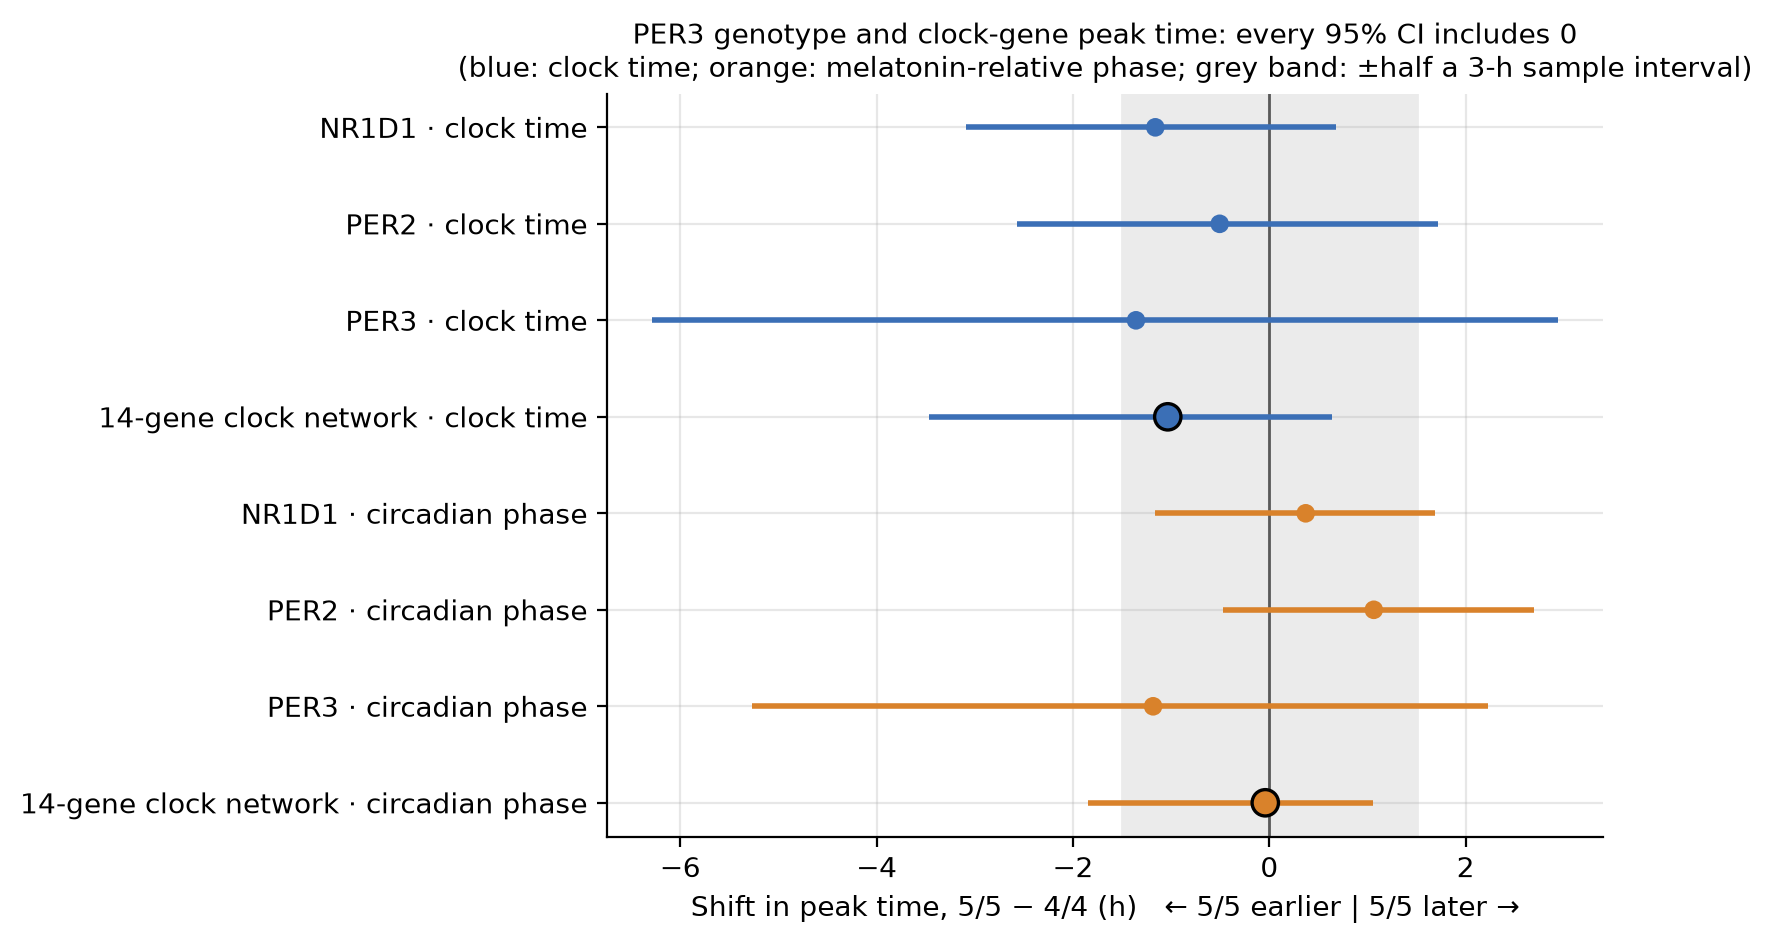

In [6]:
# @title Demo 4: saved full results
tbl = config.TABLES_DIR
shift = pd.read_csv(tbl / "acrophase_genotype_tests.csv")
show = shift.loc[shift.sample_set == "Primary",
                 ["gene", "time_base", "n_44", "n_55", "shift_h", "ci_lower_h", "ci_upper_h", "permutation_q"]]
display(show.round(2))
ml_res = pd.read_csv(tbl / "ml_phase_prediction.csv")
display(ml_res[["model", "median_abs_error_h", "median_ci95_low_h", "median_ci95_high_h"]].round(2))
display(Image(str(config.FIGURES_DIR / "conclusions_genotype_shifts.png"), width=900))